In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
import yfinance as yf
from scipy.stats import norm
from scipy.stats import multivariate_t
from scipy.stats import t

In [3]:
tickers=['JPM','AIG','GS','MS','AXP','C']
weights=np.array([1/6]*6)
prices=yf.download(tickers,start='2007-1-1',end='2008-12-31',auto_adjust=False)['Adj Close']

[*********************100%***********************]  6 of 6 completed


In [4]:
prices.head()

Ticker,AIG,AXP,C,GS,JPM,MS
Date,,,,,,
2007-01-03,862.321716,44.762249,365.170166,145.263977,29.113945,44.136066
2007-01-04,854.673035,44.435936,363.914368,143.910675,29.186628,44.292881
2007-01-05,850.729065,43.850098,361.997498,144.055435,28.944382,43.725113
2007-01-08,854.912048,44.265377,363.848297,147.442337,29.041277,43.990074
2007-01-09,852.043274,43.983604,360.675629,147.695755,28.920137,43.887329


In [5]:
ticker=['^DJI']
market_prices=yf.download(ticker,start='2007-1-1',end='2008-12-31',auto_adjust=False)['Adj Close']

[*********************100%***********************]  1 of 1 completed


In [6]:
market_returns=market_prices.ffill().pct_change().dropna()
market_returns

Ticker,^DJI
Date,
2007-01-04,0.000495
2007-01-05,-0.006625
2007-01-08,0.002055
2007-01-09,-0.000555
2007-01-10,0.002059
...,...
2008-12-23,-0.011761
2008-12-24,0.005819
2008-12-26,0.005558


In [7]:
returns=prices.ffill().pct_change().dropna()
returns

Ticker,AIG,AXP,C,GS,JPM,MS
Date,,,,,,
2007-01-04,-0.008870,-0.007290,-0.003439,-0.009316,0.002497,0.003553
2007-01-05,-0.004615,-0.013184,-0.005267,0.001006,-0.008300,-0.012818
2007-01-08,0.004917,0.009470,0.005113,0.023511,0.003348,0.006060
2007-01-09,-0.003356,-0.006366,-0.008720,0.001719,-0.004171,-0.002336
2007-01-10,0.001263,-0.000675,-0.008063,0.019747,0.007330,0.008407
...,...,...,...,...,...,...
2008-12-23,-0.037267,-0.024972,-0.034074,-0.023377,-0.023810,-0.009602
2008-12-24,0.006452,0.000556,0.039877,0.016489,0.025421,0.004155
2008-12-26,0.006410,-0.003339,-0.007374,-0.006149,-0.001675,0.010345


In [8]:
portfolio_returns=returns.dot(weights)
portfolio_returns

Date
2007-01-04   -0.003811
2007-01-05   -0.007196
2007-01-08    0.008736
2007-01-09   -0.003872
2007-01-10    0.004668
                ...   
2008-12-23   -0.025517
2008-12-24    0.015492
2008-12-26   -0.000297
2008-12-29   -0.004013
2008-12-30    0.031836
Length: 502, dtype: float64

In [9]:
aligned_data=pd.concat([portfolio_returns,market_returns],axis=1,join="inner").dropna()
aligned_data.columns=['portfolio','market']
portfolio_returns=aligned_data['portfolio']
market_returns=aligned_data['market']

In [10]:
betas=returns.apply(
    lambda x:x.cov(market_returns)/market_returns.var()
)
round(betas,2)

Ticker
AIG    2.34
AXP    1.59
C      1.95
GS     1.51
JPM    1.59
MS     2.56
dtype: float64

In [11]:
individual_var=returns.quantile(0.01)
individual_var

Ticker
AIG   -0.212127
AXP   -0.104523
C     -0.151329
GS    -0.110383
JPM   -0.114114
MS    -0.168831
Name: 0.01, dtype: float64

In [12]:
individual_es=returns[returns<=individual_var].mean()
individual_es

Ticker
AIG   -0.361745
AXP   -0.132000
C     -0.209322
GS    -0.131256
JPM   -0.145478
MS    -0.228652
dtype: float64

In [13]:
individual_volatility=returns.std()*np.sqrt(252)
round(individual_volatility,2)

Ticker
AIG    1.11
AXP    0.55
C      0.85
GS     0.61
JPM    0.63
MS     1.02
dtype: float64

In [14]:
var=np.percentile(portfolio_returns,1)
es=portfolio_returns[portfolio_returns<=var].mean()
print("Historical Var:",var)
print("Historical ES:",es)

Historical Var: -0.13987639719695769
Historical ES: -0.17092065079025084


In [15]:
mu=portfolio_returns.mean()
sigma=portfolio_returns.std()
z=norm.ppf(0.01)
phi=norm.pdf(z)
parametric_var_normal=mu+z*sigma
parametric_es_normal=mu-sigma*phi/0.01
print("Parametric Var Normal:",parametric_var_normal)
print("Parametric ES Normal:",parametric_es_normal)

Parametric Var Normal: -0.09937968354554996
Parametric ES Normal: -0.11358508618942452


In [16]:
df=t.fit(portfolio_returns)
print("DF:",df)

DF: (np.float64(1.7988582138564477), np.float64(-0.0016080626453384035), np.float64(0.017192599679412283))


In [17]:
df,loc,scale=t.fit(portfolio_returns)
alpha=0.01
t_score=t.ppf(alpha,df)
pdf_cutoff=t.pdf(t_score,df)
parametric_var_t=loc+(t_score*scale)
parametric_es_t=loc-(scale*(pdf_cutoff/alpha)*((df+t_score**2)/(df-1)))
print("Parametric Var T:",parametric_var_t)
print("Parametric ES T:",parametric_es_t)

Parametric Var T: -0.14137892117526793
Parametric ES T: -0.31858177662416454


In [18]:
mu=returns.mean()
cov=returns.cov()
simulated=np.random.multivariate_normal(mu,cov,10000)
simulated_returns=simulated.dot(weights)
montecarlo_var_normal=np.percentile(simulated_returns,1)
montecarlo_es_normal=simulated_returns[simulated_returns<=montecarlo_var_normal].mean()
print("MonteCarlo Var Normal:",montecarlo_var_normal)
print("MonteCarlo ES Normal:",montecarlo_es_normal)

MonteCarlo Var Normal: -0.09772016554965526
MonteCarlo ES Normal: -0.11287017283204054


In [19]:
df,loc,scale=t.fit(portfolio_returns)
simulated_returns=t.rvs(df=df,loc=loc,scale=scale,random_state=42,size=10000)
montecarlo_var_t=np.percentile(simulated_returns,1)
montecarlo_es_t=simulated_returns[simulated_returns<=montecarlo_var_t].mean()
print("MonteCarlo Var T:",montecarlo_var_t)
print("MonteCarlo ES T:",montecarlo_es_t)

MonteCarlo Var T: -0.13291098778641797
MonteCarlo ES T: -0.27348423637434804


In [20]:
# Daily Rebalancing

In [21]:
initial = 10000
port_returns = returns.mean(axis=1)
rebalanced = initial * (1 + port_returns).cumprod()

In [22]:
# Buy and Hold 

In [23]:
shares = (initial / len(tickers)) / prices.iloc[0]
buy_hold = (prices * shares).sum(axis=1)

In [24]:
print(f"Rebalanced: ${rebalanced.iloc[-1]:,.0f} ({rebalanced.iloc[-1] / initial - 1:.2%})")
print(f"Buy & hold: ${buy_hold.iloc[-1]:,.0f} ({buy_hold.iloc[-1] / initial - 1:.2%})")

Rebalanced: $2,536 (-74.64%)
Buy & hold: $2,996 (-70.04%)


In [25]:
# Total return per stock: 

In [26]:
total_returns = prices.iloc[-1] / prices.iloc[0] - 1

print(total_returns.sort_values().map("{:.2%}".format))

Ticker
AIG    -97.77%
C      -86.42%
MS     -76.53%
AXP    -69.44%
GS     -58.49%
JPM    -31.60%
dtype: object


In [27]:
drawdown = rebalanced / rebalanced.cummax() - 1
print(f"Max drawdown: {drawdown.min():.2%}")

Max drawdown: -82.70%


In [28]:
# Worst Portfolio Day

In [29]:
worst_portfolio_day = portfolio_returns.idxmin()
worst_portfolio_return = portfolio_returns.min()

print(f"Worst Single Day for the Portfolio: {worst_portfolio_day.strftime('%Y-%m-%d')}")
print(f"Portfolio Single-Day Loss: {worst_portfolio_return:.2%}\n")


print("Individual Stock Performance on the Portfolio's Worst Day:")
print((returns.loc[worst_portfolio_day] * 100).round(2).astype(str) + '%')

Worst Single Day for the Portfolio: 2008-09-15
Portfolio Single-Day Loss: -20.11%

Individual Stock Performance on the Portfolio's Worst Day:
Ticker
AIG    -60.79%
AXP     -8.91%
C      -15.14%
GS     -12.13%
JPM    -10.13%
MS     -13.54%
Name: 2008-09-15 00:00:00, dtype: object


In [ ]:
#ROLLING AVERAGE CORRELATION

In [37]:
WINDOW = 60   # trading days (about 3 months)
n = returns.shape[1]
upper = np.triu_indices(n, k=1)   # each pair once, no diagonal

avg_corr = pd.Series(
    [np.nan if i < WINDOW else
     returns.iloc[i - WINDOW:i].corr().values[upper].mean()
     for i in range(len(returns))],
    index=returns.index, name="avg_corr")

full_corr = returns.corr().values[upper].mean()
print(f"Average pairwise correlation, full period: {full_corr:.2f}")
print(f"2007 average of rolling series: {avg_corr['2007'].mean():.2f}")
print(f"2008 average of rolling series: {avg_corr['2008'].mean():.2f}")
print(f"Peak rolling correlation: {avg_corr.max():.2f} on {avg_corr.idxmax():%b %d, %Y}")





Average pairwise correlation, full period: 0.65
2007 average of rolling series: 0.72
2008 average of rolling series: 0.71
Peak rolling correlation: 0.82 on Sep 19, 2007


In [38]:
# RISK CONTRIBUTION (equal weights, i.e. the rebalanced portfolio)

In [39]:
w = np.full(n, 1 / n)
cov = returns.cov().values

# Volatility contribution: weight * (cov @ weights) / portfolio variance. Sums to 100%.
vol_contrib = pd.Series(w * (cov @ w) / (w @ cov @ w), index=returns.columns)

# Tail contribution: each stock's share of the loss on the portfolio's worst 1% of days
port_ret = returns.mean(axis=1)
worst_days = port_ret <= port_ret.quantile(0.01)
tail_contrib = (returns[worst_days] * w).mean() / port_ret[worst_days].mean()

contrib = pd.DataFrame({"Volatility": vol_contrib, "Worst 1% days": tail_contrib}) \
            .sort_values("Volatility", ascending=False)
print((contrib * 100).round(1).astype(str) + "%")

       Volatility Worst 1% days
Ticker                         
AIG         22.1%         30.8%
MS          21.5%         19.0%
C           18.6%         15.2%
GS          13.1%         12.5%
JPM         12.9%         11.9%
AXP         11.8%         10.6%


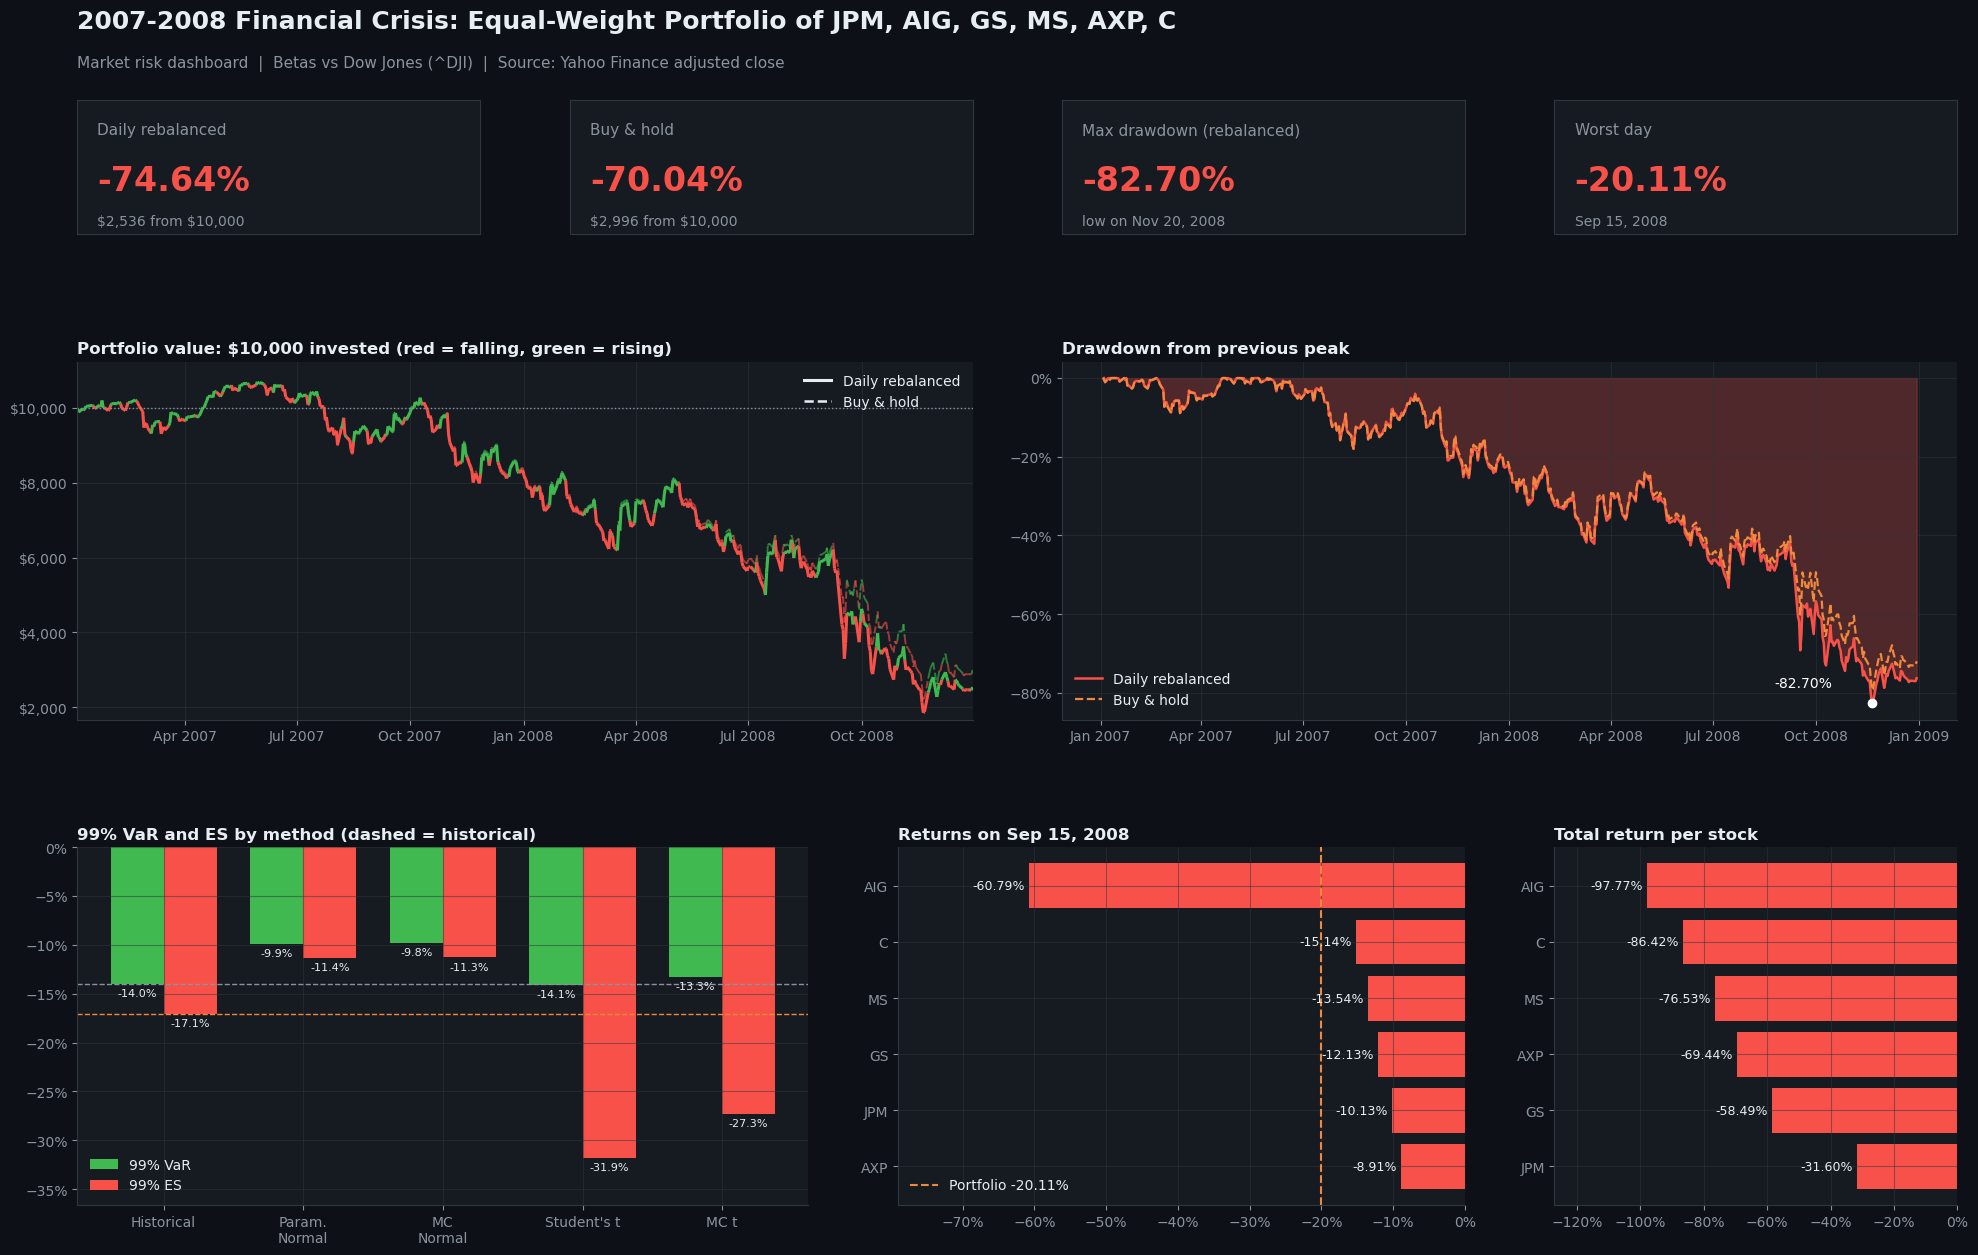

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import matplotlib.dates as mdates

# ---------- Theme ----------
BG, PANEL, GRID, TXT, MUTED = "#0d1117", "#161b22", "#30363d", "#e6edf3", "#8b949e"
RED, GREEN, BLUE, ORANGE = "#f85149", "#3fb950", "#58a6ff", "#f0883e"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": PANEL, "axes.edgecolor": GRID,
    "axes.labelcolor": TXT, "text.color": TXT, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.alpha": 0.5, "axes.grid": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlecolor": TXT,
    "axes.titlelocation": "left", "font.size": 10,
})

def red_green_line(ax, series, linestyle="-", window=5, lw=2, alpha=1.0):
    """Line coloured red where price fell over the last `window` days, green where it rose."""
    x = mdates.date2num(series.index)
    y = series.values
    pts = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    change = series.diff(window).fillna(0).values[1:]
    colors = np.where(change < 0, RED, GREEN)
    lc = LineCollection(segs, colors=colors, linewidths=lw, linestyles=linestyle, alpha=alpha)
    ax.add_collection(lc)
    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(min(ax.get_ylim()[0], y.min() * 0.95), max(ax.get_ylim()[1], y.max() * 1.05))
    ax.xaxis_date()

# ---------- Numbers used in the dashboard ----------
dd_reb = rebalanced / rebalanced.cummax() - 1
dd_bh = buy_hold / buy_hold.cummax() - 1
reb_ret = rebalanced.iloc[-1] / initial - 1
bh_ret = buy_hold.iloc[-1] / initial - 1

# ---------- Layout ----------
fig = plt.figure(figsize=(20, 13))
gs = fig.add_gridspec(3, 12, height_ratios=[0.45, 1.2, 1.2], hspace=0.45, wspace=1.2,
                      left=0.04, right=0.98, top=0.90, bottom=0.05)
fig.suptitle("2007-2008 Financial Crisis: Equal-Weight Portfolio of JPM, AIG, GS, MS, AXP, C",
             x=0.04, y=0.97, ha="left", fontsize=18, fontweight="bold")
fig.text(0.04, 0.925, "Market risk dashboard  |  Betas vs Dow Jones (^DJI)  |  Source: Yahoo Finance adjusted close",
         color=MUTED, fontsize=11)

# ---------- KPI tiles ----------
kpis = [
    ("Daily rebalanced", f"{reb_ret:.2%}", f"\\${rebalanced.iloc[-1]:,.0f} from \\$10,000"),
    ("Buy & hold", f"{bh_ret:.2%}", f"\\${buy_hold.iloc[-1]:,.0f} from \\$10,000"),
    ("Max drawdown (rebalanced)", f"{dd_reb.min():.2%}", f"low on {dd_reb.idxmin():%b %d, %Y}"),
    ("Worst day", f"{worst_portfolio_return:.2%}", f"{worst_portfolio_day:%b %d, %Y}"),
]
for i, (label, value, sub) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i * 3:(i + 1) * 3])
    ax.set_facecolor(PANEL); ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(GRID)
    ax.text(0.05, 0.78, label, color=MUTED, fontsize=11, transform=ax.transAxes, va="center")
    ax.text(0.05, 0.40, value, color=RED, fontsize=24, fontweight="bold", transform=ax.transAxes, va="center")
    ax.text(0.05, 0.10, sub, color=MUTED, fontsize=10, transform=ax.transAxes, va="center")

# ---------- 1. Portfolio value (red = falling, green = rising) ----------
ax1 = fig.add_subplot(gs[1, :6])
ax1.set_ylim(rebalanced.min() * 0.9, rebalanced.max() * 1.05)
red_green_line(ax1, buy_hold, linestyle="--", lw=1.4, alpha=0.6)
red_green_line(ax1, rebalanced, linestyle="-", lw=2.2)
ax1.axhline(initial, color=MUTED, ls=":", lw=1)
ax1.set_title("Portfolio value: $10,000 invested (red = falling, green = rising)")
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax1.legend(handles=[Line2D([0], [0], color=TXT, lw=2.2, ls="-", label="Daily rebalanced"),
                    Line2D([0], [0], color=TXT, lw=1.8, ls="--", label="Buy & hold")],
           frameon=False, loc="upper right", labelcolor=TXT)

# ---------- 2. Drawdown ----------
ax2 = fig.add_subplot(gs[1, 6:])
ax2.fill_between(dd_reb.index, dd_reb * 100, 0, color=RED, alpha=0.25)
ax2.plot(dd_reb * 100, color=RED, lw=1.8, label="Daily rebalanced")
ax2.plot(dd_bh * 100, color=ORANGE, lw=1.6, ls="--", label="Buy & hold")
ax2.scatter(dd_reb.idxmin(), dd_reb.min() * 100, color="white", zorder=5)
ax2.annotate(f"{dd_reb.min():.2%}", (dd_reb.idxmin(), dd_reb.min() * 100),
             xytext=(-70, 12), textcoords="offset points", color="white")
ax2.set_title("Drawdown from previous peak")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax2.legend(frameon=False, loc="lower left", labelcolor=TXT)

# ---------- 3. VaR vs ES ----------
ax3 = fig.add_subplot(gs[2, :5])
methods = ["Historical", "Param.\nNormal", "MC\nNormal", "Student's t", "MC t"]
var_vals = np.array([var, parametric_var_normal, montecarlo_var_normal,
                     parametric_var_t, montecarlo_var_t]) * 100
es_vals = np.array([es, parametric_es_normal, montecarlo_es_normal,
                    parametric_es_t, montecarlo_es_t]) * 100
x, w = np.arange(len(methods)), 0.38
b1 = ax3.bar(x - w / 2, var_vals, w, color=GREEN, label="99% VaR")
b2 = ax3.bar(x + w / 2, es_vals, w, color=RED, label="99% ES")
ax3.bar_label(b1, fmt="%.1f%%", padding=3, fontsize=8, color=TXT)
ax3.bar_label(b2, fmt="%.1f%%", padding=3, fontsize=8, color=TXT)
ax3.axhline(var * 100, color=MUTED, ls="--", lw=1)
ax3.axhline(es * 100, color=ORANGE, ls="--", lw=1)
ax3.set_xticks(x); ax3.set_xticklabels(methods)
ax3.margins(y=0.15)
ax3.set_title("99% VaR and ES by method (dashed = historical)")
ax3.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax3.legend(frameon=False, loc="lower left", labelcolor=TXT)

# ---------- 4. Lehman day ----------
ax4 = fig.add_subplot(gs[2, 5:9])
lehman = (returns.loc[worst_portfolio_day] * 100).sort_values(ascending=False)
bars = ax4.barh(lehman.index, lehman.values, color=RED)
ax4.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9, color=TXT)
ax4.axvline(worst_portfolio_return * 100, color=ORANGE, ls="--", lw=1.5,
            label=f"Portfolio {worst_portfolio_return:.2%}")
ax4.margins(x=0.3)
ax4.set_title(f"Returns on {worst_portfolio_day:%b %d, %Y}")
ax4.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax4.legend(frameon=False, loc="lower left", labelcolor=TXT)

# ---------- 5. Total return per stock ----------
ax5 = fig.add_subplot(gs[2, 9:])
tr = (total_returns * 100).sort_values(ascending=False)
bars = ax5.barh(tr.index, tr.values, color=np.where(tr.values < 0, RED, GREEN))
ax5.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9, color=TXT)
ax5.margins(x=0.3)
ax5.set_title("Total return per stock")
ax5.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

plt.savefig("risk_dashboard.png", dpi=200, bbox_inches="tight", facecolor=BG)
plt.show()

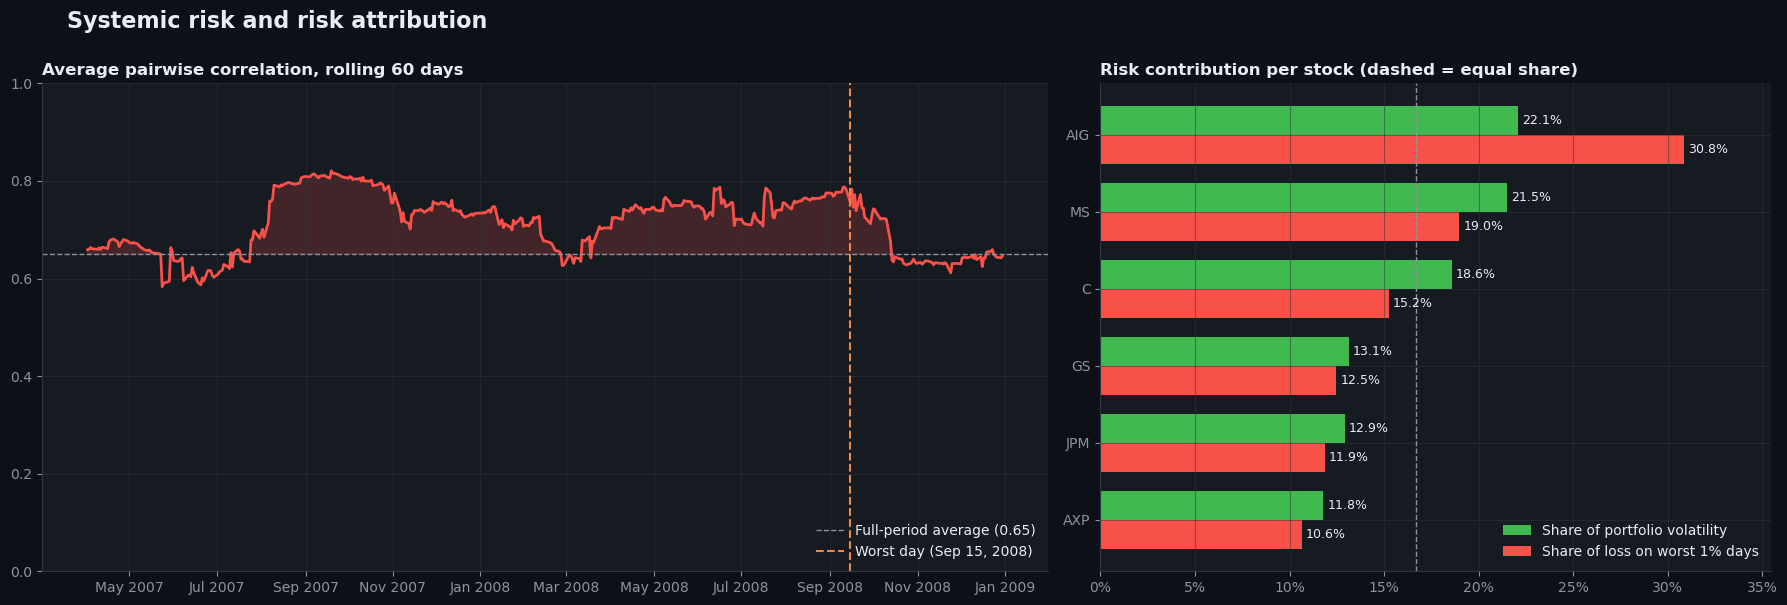

In [40]:
BG, PANEL, GRID, TXT, MUTED = "#0d1117", "#161b22", "#30363d", "#e6edf3", "#8b949e"
RED, GREEN, BLUE, ORANGE = "#f85149", "#3fb950", "#58a6ff", "#f0883e"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": PANEL, "axes.edgecolor": GRID,
    "axes.labelcolor": TXT, "text.color": TXT, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.alpha": 0.5, "axes.grid": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlecolor": TXT,
    "axes.titlelocation": "left", "font.size": 10,
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.5, 1]})
fig.suptitle("Systemic risk and risk attribution", x=0.04, y=1.0, ha="left",
             fontsize=16, fontweight="bold")

# --- Rolling correlation ---
ax1.plot(avg_corr, color=RED, lw=2)
ax1.fill_between(avg_corr.index, avg_corr, full_corr, where=avg_corr >= full_corr,
                 color=RED, alpha=0.2)
ax1.axhline(full_corr, color=MUTED, ls="--", lw=1, label=f"Full-period average ({full_corr:.2f})")
ax1.axvline(worst_portfolio_day, color=ORANGE, ls="--", lw=1.5,
            label=f"Worst day ({worst_portfolio_day:%b %d, %Y})")
ax1.set_ylim(0, 1)
ax1.set_title(f"Average pairwise correlation, rolling {WINDOW} days")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax1.legend(frameon=False, loc="lower right", labelcolor=TXT)

# --- Risk contribution ---
y = np.arange(len(contrib))
h = 0.38
b1 = ax2.barh(y - h / 2, contrib["Volatility"] * 100, h, color=GREEN, label="Share of portfolio volatility")
b2 = ax2.barh(y + h / 2, contrib["Worst 1% days"] * 100, h, color=RED, label="Share of loss on worst 1% days")
ax2.bar_label(b1, fmt="%.1f%%", padding=3, fontsize=9, color=TXT)
ax2.bar_label(b2, fmt="%.1f%%", padding=3, fontsize=9, color=TXT)
ax2.axvline(100 / n, color=MUTED, ls="--", lw=1)   # equal-share line (16.7%)
ax2.set_yticks(y)
ax2.set_yticklabels(contrib.index)
ax2.invert_yaxis()
ax2.margins(x=0.15)
ax2.set_title("Risk contribution per stock (dashed = equal share)")
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.legend(frameon=False, loc="lower right", labelcolor=TXT)

plt.tight_layout()
plt.savefig("risk_extensions.png", dpi=200, bbox_inches="tight", facecolor=BG)
plt.show()